# Handling missing data

### Options: 
#### 1.Removing them 
#### 2.IMpute: 1.Univariate, 2.Multivariate

# **Removing missing values**

## CCA(complete case analysis)

### discarding observation(row) where values in any of the variable(column) are missing 

### It literally means to only analyzing those observations for which there is information in all of the variables in the dataset

## Assumptions for CCA:
### your data is missing completely at random(MCAR)

### 5% of data missing

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv('data_science_job.csv')

In [3]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [4]:
df.isnull().mean()*100 #percentage of missing data

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

### CCA applied to missing data <5%

In [5]:
cols = [var for var in df.columns if df[var].isnull().mean() < 0.05 and df[var].isnull().mean()>0]

In [6]:
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [7]:
df[cols].sample(15)

,city_development_index,enrolled_university,education_level,experience,training_hours
10885,0.926,no_enrollment,Phd,20.0,13.0
18096,0.926,no_enrollment,Graduate,14.0,68.0
14918,0.698,no_enrollment,Graduate,9.0,64.0
12565,0.939,no_enrollment,Masters,10.0,42.0
10907,0.920,no_enrollment,Masters,20.0,37.0
1354,0.920,no_enrollment,Masters,17.0,11.0
18776,0.890,no_enrollment,High School,11.0,130.0
12716,0.910,Full time course,Graduate,5.0,114.0
16903,0.624,Full time course,Graduate,2.0,146.0
11082,0.847,no_enrollment,Graduate,14.0,33.0


In [8]:
len(df[cols].dropna())/len(df) #remaining percentage after dropping 

0.8968577095730244

## the distribution should be preserved in the numerical data after preforming CCA

In [9]:
df_new = df[cols].dropna()
df.shape, df_new.shape

((19158, 13), (17182, 5))

In [10]:
import seaborn as sns

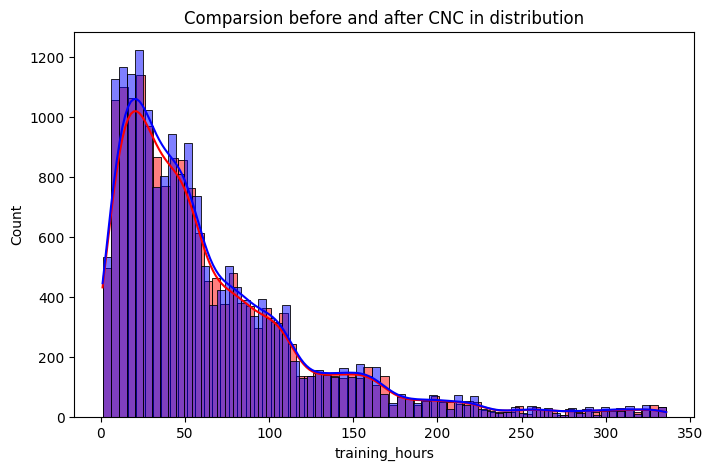

In [11]:
fig, ax = plt.subplots(figsize = (8,5))
sns.histplot(df_new['training_hours'],color = "red",ax = ax, kde= True, label = 'Dataset after CNC')
sns.histplot(df['training_hours'],color = "blue",ax = ax, kde= True, label = 'Dataset before CNC')
plt.title("Comparsion before and after CNC in distribution")
plt.show()

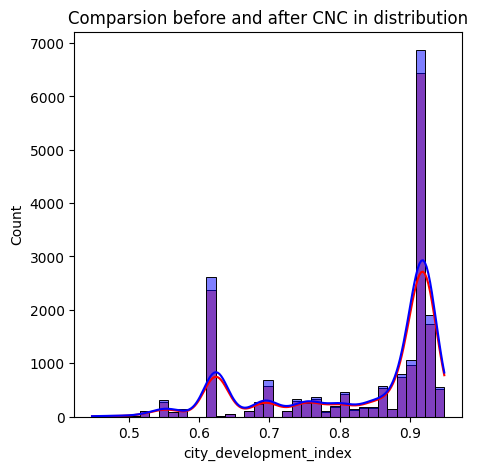

In [12]:
fig, ax = plt.subplots(figsize = (5,5))
sns.histplot(df_new['city_development_index'],color = "red",ax = ax, kde= True, label = 'Dataset after CNC')
sns.histplot(df['city_development_index'],color = "blue",ax = ax, kde= True, label = 'Dataset before CNC')
plt.title("Comparsion before and after CNC in distribution")
plt.show()

## for categorical columns

In [14]:
df['enrolled_university'].value_counts()

enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
Name: count, dtype: int64

### the ratio of the categories should be preserved after performing CCA 

In [15]:
temp  = pd.concat([df['education_level'].value_counts()/len(df), 
                   df_new['education_level'].value_counts()/len(df)
                  ], axis=1)
temp.columns = ['original', 'cca']
temp 

,original,cca
education_level,,
Graduate,0.605387,0.555904
Masters,0.227633,0.209938
High School,0.105282,0.096304
Phd,0.021610,0.019835
Primary School,0.016077,0.014876


In [16]:
temp  = pd.concat([df['enrolled_university'].value_counts()/len(df), 
                   df_new['enrolled_university'].value_counts()/len(df)
                  ], axis=1)
temp.columns = ['original', 'cca']
temp 

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.659359
Full time course,0.196106,0.180029
Part time course,0.062533,0.057469


In [20]:
df_new.isnull().sum()

city_development_index    0
enrolled_university       0
education_level           0
experience                0
training_hours            0
dtype: int64